In [2]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import logging
import warnings

# Suppress warnings
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

# Activate Cambria
font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size']        = 11

print("Cambria font active and ready!")

Cambria font active and ready!


Generating demand profile...
Peak demand:    681.6 kW
Min demand:     47.5 kW
Average demand: 274.1 kW
Annual total:   2400.9 MWh


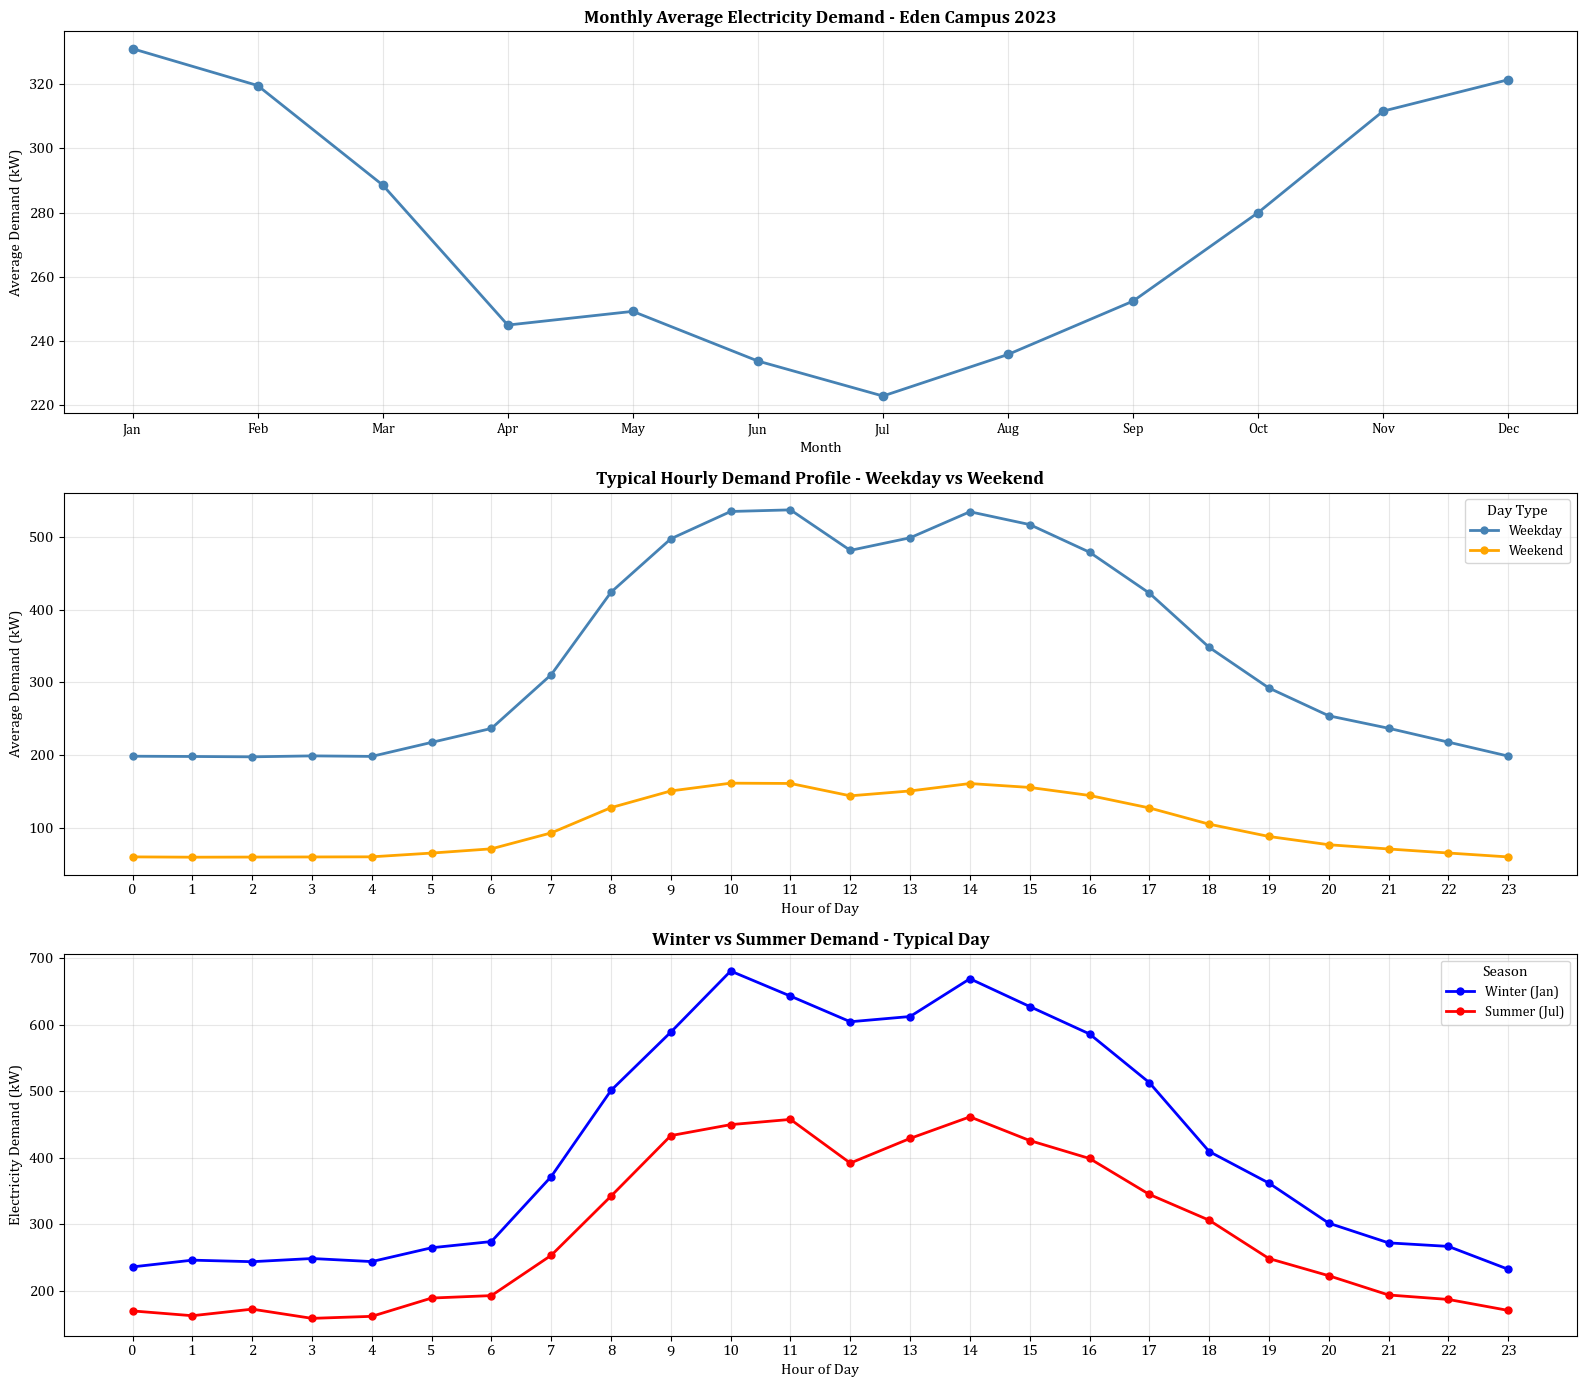

Stage 3 complete — demand profile saved!


In [4]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size']        = 11

base  = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")
hours = pd.date_range(start='2023-01-01', end='2023-12-31 23:00', freq='h')
np.random.seed(42)

def generate_demand(timestamp):
    hour   = timestamp.hour
    month  = timestamp.month
    day    = timestamp.weekday()
    base_d = 150
    seasonal = {1:1.3, 2:1.25, 3:1.1, 4:1.0, 5:0.95, 6:0.9,
                7:0.9, 8:0.9, 9:1.0, 10:1.1, 11:1.2, 12:1.3}
    season_factor  = seasonal[month]
    weekend_factor = 0.3 if day >= 5 else 1.0
    hourly_profile = {
        0:0.1, 1:0.1, 2:0.1, 3:0.1, 4:0.1, 5:0.15,
        6:0.2, 7:0.4, 8:0.7, 9:0.9, 10:1.0, 11:1.0,
        12:0.85, 13:0.9, 14:1.0, 15:0.95, 16:0.85, 17:0.7,
        18:0.5, 19:0.35, 20:0.25, 21:0.2, 22:0.15, 23:0.1}
    hour_factor = hourly_profile[hour]
    peak   = 500
    demand = (base_d + (peak - base_d) * hour_factor) * season_factor * weekend_factor
    return demand * np.random.uniform(0.95, 1.05)

print("Generating demand profile...")
demand_values = [generate_demand(ts) for ts in hours]
demand_series = pd.Series(demand_values, index=hours, name='demand_kW')

csv_path = os.path.join(base, "01_data/demand", "eden_campus_demand_2023.csv")
demand_series.to_csv(csv_path)

print(f"Peak demand:    {demand_series.max():.1f} kW")
print(f"Min demand:     {demand_series.min():.1f} kW")
print(f"Average demand: {demand_series.mean():.1f} kW")
print(f"Annual total:   {demand_series.sum()/1000:.1f} MWh")

months = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

monthly_avg = demand_series.resample('ME').mean()
axes[0].plot(range(1, 13), monthly_avg.values,
             color='steelblue', marker='o', linewidth=2, markersize=6)
axes[0].set_title('Monthly Average Electricity Demand - Eden Campus 2023',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Average Demand (kW)', fontsize=11)
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(months, fontsize=10)
axes[0].grid(True, alpha=0.3)

weekday_data = demand_series[demand_series.index.weekday < 5].groupby(
    demand_series[demand_series.index.weekday < 5].index.hour).mean()
weekend_data = demand_series[demand_series.index.weekday >= 5].groupby(
    demand_series[demand_series.index.weekday >= 5].index.hour).mean()

axes[1].plot(range(24), weekday_data.values, color='steelblue',
             marker='o', linewidth=2, markersize=5, label='Weekday')
axes[1].plot(range(24), weekend_data.values, color='orange',
             marker='o', linewidth=2, markersize=5, label='Weekend')
axes[1].set_title('Typical Hourly Demand Profile - Weekday vs Weekend',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Average Demand (kW)', fontsize=11)
axes[1].set_xlabel('Hour of Day', fontsize=11)
axes[1].set_xticks(range(24))
axes[1].legend(title='Day Type', fontsize=10)
axes[1].grid(True, alpha=0.3)

winter_day = demand_series['2023-01-10']
summer_day = demand_series['2023-07-10']

axes[2].plot(range(24), winter_day.values, color='blue',
             marker='o', linewidth=2, markersize=5, label='Winter (Jan)')
axes[2].plot(range(24), summer_day.values, color='red',
             marker='o', linewidth=2, markersize=5, label='Summer (Jul)')
axes[2].set_title('Winter vs Summer Demand - Typical Day',
                   fontsize=13, fontweight='bold')
axes[2].set_ylabel('Electricity Demand (kW)', fontsize=11)
axes[2].set_xlabel('Hour of Day', fontsize=11)
axes[2].set_xticks(range(24))
axes[2].legend(title='Season', fontsize=10)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(base, "01_data/demand", "eden_campus_demand_profile.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Stage 3 complete — demand profile saved!")